(c) Solve the phase equation to show tan(πφ(t)) = tan(πφ0)e−2t. Then simulate the voltage equations with the infinite threshold and reset replaced by ±L, L = 200, starting neuron 1 at reset and neuron 2 a fraction φ0 = 0.4 of a cycle behind on the uncoupled orbit. Measure the lag once per cycle from spike times, φk = (t(2)k − t(1)k)/(t(1)k+1 − t(1)k), and plot it against the prediction for  = 0.02. Fit the decay rate of tan(πφk) for  = 0.005, 0.02, 0.05 and compare with 2. Why is a symmetric cutoff ±L important?

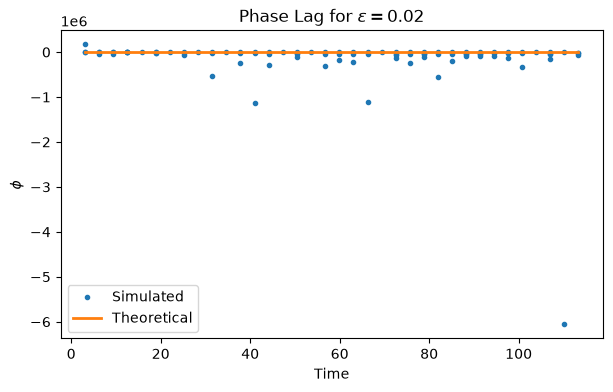

Decay rate fitting


C:\Users\laurm\AppData\Local\Temp\ipykernel_30280\3796803771.py:117: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  fit = linregress(t_fit, y_fit)


epsilon: 0.0050, measured rate: nan, predicted rate: 0.0100
epsilon: 0.0200, measured rate: 0.0383, predicted rate: 0.0400
epsilon: 0.0500, measured rate: 0.0874, predicted rate: 0.1000


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.stats import linregress

L = 200
phi_0 = 0.4

def phi_prediction(t, epsilon, phi_0 = 0.4):
    return np.arctan(np.tan(np.pi * phi_0) * np.exp(-2 * epsilon * t)) / np.pi

def QIF_rhs(t, v, epsilon):
    v1, v2 = v
    dv1 = 1 + v1**2 + epsilon * (v2 - v1)
    dv2 = 1 + v2**2 + epsilon * (v1 - v2)
    return [dv1, dv2]

def QIF_sim(epsilon, num_cycles = 100, dt = 1e-3):
    v1_0 = -L   # resting state
    theta2_0 = 0.6  # 1 - 0.4 = 0.6
    v2_0 = -1 / np.tan(np.pi * theta2_0)

    t = 0.0
    v = np.array([v1_0, v2_0])

    spike_times_1 = []
    spike_times_2 = []
    times = []
    voltages = []

    # spike data accumulation
    while len(spike_times_1) < num_cycles + 1:
        sol = solve_ivp(QIF_rhs, (t, t + dt), v, args = (epsilon,), max_step = dt, rtol = 1e-8, atol = 1e-10)
        t_values = sol.t
        v_values = sol.y.T

        for k in range(1, len(t_values)):
            prior_v = v_values[k - 1]
            new_v = v_values[k]
            tk = t_values[k]

            # cutoff for +L for neuron 1
            if prior_v[0] < L and new_v[0] >= L:
                spike_times_1.append(tk)
                new_v[0] = -L

            # cutoff for +L for neuron 2
            if prior_v[1] < L and new_v[1] >= L:
                spike_times_2.append(tk)
                new_v[1] = -L

            times.append(tk)
            voltages.append(new_v.copy())
        
        t = t_values[-1]
        v = v_values[-1].copy()

        # reset voltage after crossing th
        if v[0] >= L:
            v[0] = -L
        if v[1] >= L:
            v[1] = -L

    return (
        np.array(spike_times_1),
        np.array(spike_times_2),
        np.array(times),
        np.array(voltages)
    )

# Measure the lag
def calculate_phi_val(spike_times_1, spike_times_2):
    phi = []
    t_measure = []

    for k in range(min(len(spike_times_1) - 1, len(spike_times_2))):
        t1 = spike_times_1[k]
        t2 = spike_times_2[k]
        period = spike_times_1[k + 1] - spike_times_1[k]
        phi_k = (t2 - t1) / period
        phi.append(phi_k)
        t_measure.append(t1)

    return np.array(t_measure), np.array(phi)

# lag for when epsilon = 0.02
epsilon = 0.02

spikes1, spikes2, times, voltages = QIF_sim(epsilon, num_cycles=100) #dt=1e-3)

t_phi, phi_sim = calculate_phi_val(spikes1, spikes2)

phi_theoretical = phi_prediction(t_phi, epsilon, phi_0)

plt.figure(figsize = (7, 4))
plt.plot(t_phi, phi_sim, 'o', ms = 3, label='Simulated')
plt.plot(t_phi, phi_theoretical, lw = 2, label='Theoretical')
plt.xlabel("Time")
plt.ylabel(r"$\phi$")
plt.title(r"Phase Lag for $\epsilon = 0.02$")
plt.legend()
plt.show()

# Fit the decay rate
epsilon_vals = [0.005, 0.02, 0.05]
print("Decay rate fitting")

for e in epsilon_vals:
    spikes1, spikes2, _, _ = QIF_sim(e, num_cycles=100)
    t_phi, phi_sim = calculate_phi_val(spikes1, spikes2)

    # ignore if too close to 0
    valid = ((phi_sim > 0) & (phi_sim < 0.5))
    t_fit = t_phi[valid]
    y_fit = np.log(np.tan(np.pi * phi_sim[valid]))

    fit = linregress(t_fit, y_fit)
    measured_rate = -fit.slope
    predicted_rate = 2 * e

    print(f"epsilon: {e:.4f}, measured rate: {measured_rate:.4f}, predicted rate: {predicted_rate:.4f}")
